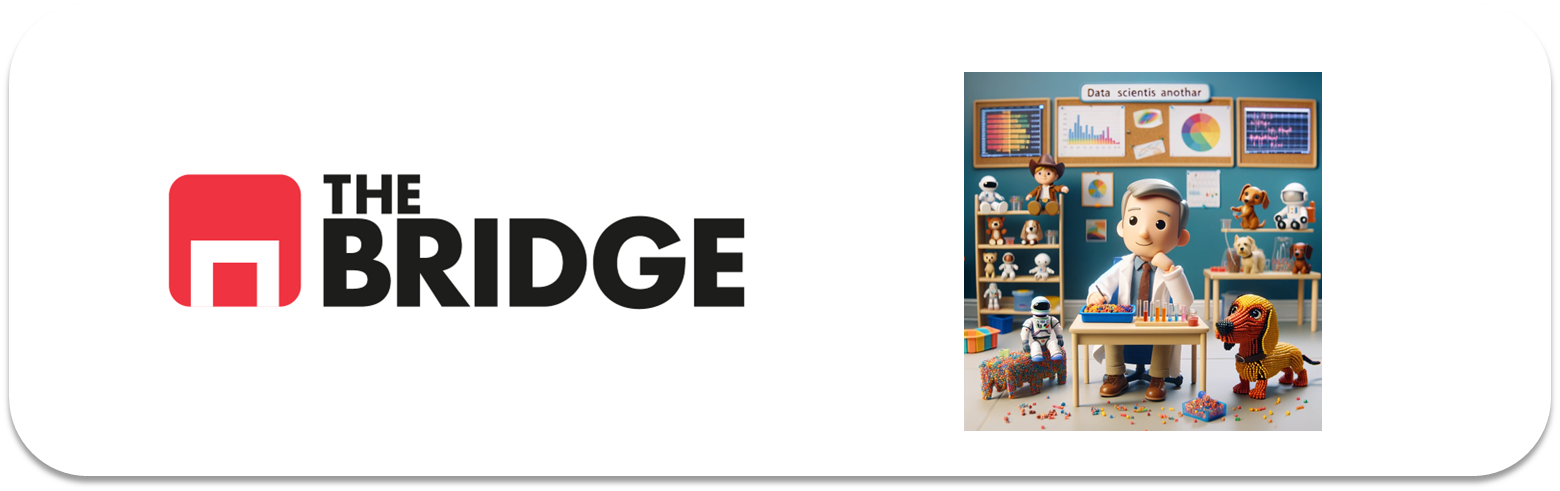

## Análisis de Datos: Detección de Outliers

Un outlier es una observación anormal y extrema en un conjunto de valores relacionados, como los de nuestras variables o los de una muestra estadística. Estas anomalías son datos que puede afectar potencialmente a la estimación de los parámetros del mismo.

Se trata de datos que no son consistentes con el resto.

Veamos un ejemplo de cómo afectan los outliers al análisis. Imaginemos que tenemos una muestra con alturas de los alumnos dentro de una clase

In [1]:
import statistics

alturas = [1.65, 1.80, 1.72, 1.68, 1.75, 1.85, 1.62, 1.79, 1.82, 1.69]

print("Media de alturas:  ", round(statistics.mean(alturas), 3))
print("Mediana de alturas:", round(statistics.median(alturas), 3))

Media de alturas:   1.737
Mediana de alturas: 1.735


La media y la mediana prácticamente coinciden: con datos así de concentrados, cualquiera de las dos representa bien la altura típica. Ahora imaginemos que se incorporan a la clase dos futuros jugadores de la NBA.

In [2]:
alturas = [1.65, 1.80, 1.72, 1.68, 1.75, 1.85, 1.62, 1.79, 1.82, 1.69, 2.18, 2.22]

print("Media de alturas:  ", round(statistics.mean(alturas), 3))
print("Mediana de alturas:", round(statistics.median(alturas), 3))

Media de alturas:   1.814
Mediana de alturas: 1.77


Con solo dos personas más, la media sube casi 8 cm, mientras que la mediana apenas se mueve. La media se deja arrastrar por los valores extremos; la mediana es **robusta**. Por eso es tan importante saber si hay outliers antes de resumir una variable.

Visto el ejemplo, tenemos dos puntos que cubrir:
1. Cómo se detectan.
2. ¿Qué decisión tomamos con ellos **para nuestro análisis**?

Vayamos por partes y apliquémoslo a nuestro caso... Por eso, sí, acertaste ejecuta estas celdas:

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from bootcampviztools import plot_combined_graphs  # funciones de visualización del curso

df_seguros = pd.read_csv("../data/Marketing-Customer-Analysis.csv")

### Detección de Outliers

La primera forma de detectar outliers es recurrir a los histogramas y a los diagramas de cajas. Por ejemplo para CLV en nuestro caso de seguros, ya lo vimos:

(2,)


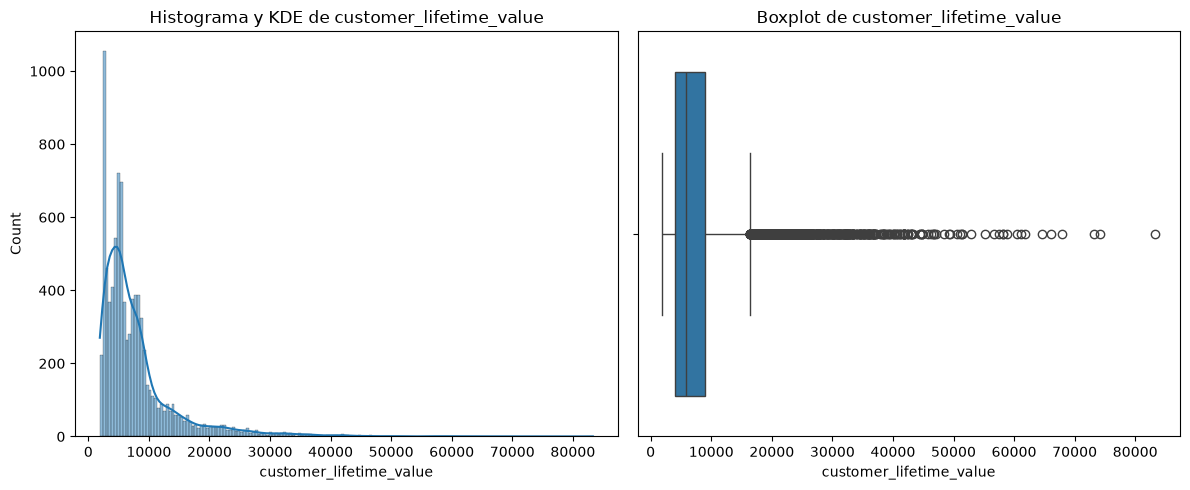

In [4]:
plot_combined_graphs(df_seguros, ["customer_lifetime_value"])

En los dos gráficos, la larga cola del histograma y los valores fuera del "maximum" del boxplot ya nos indican la presencia de valores anómalos en el rango superior (vamos que se van por la derecha)

Lo que realmente necesitamos es un umbral de corte a partir del cual podamos indicar que lo que es superior o inferior es un valor anómalo. En general este umbral depende de los datos, fíjate que para el diagrama de cajas un punto de corte está por debajo de los 20000 y en el histograma-densidad vemos que podríamos ponerlo más sobre 40000. ¿Cuál coger? ya lo sabes...depende.

1. Cuando la densidad estimada en el diagrama combinado histograma-densidad se parece a una normal (como la de la imagen), un buen criterio es [y lo explicaremos en la sesión en vivo] considerar outliers los valores que se alejan de la media más de 2 o 3 desviaciones estándar (valores < media - n·std o > media + n·std; la normal es simétrica respecto a la media, por eso hay que mirar a derecha e izquierda).

|Valor de n | % de valores dentro del rango (en una normal)|
|-|-|
|1|68 %|
|2|95 %|
|3|99,7 %|

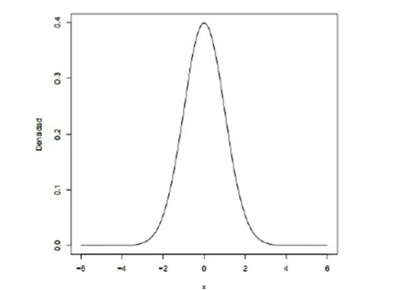

2. Si nuestra densidad no tiene pinta de gaussiana, como le pasa a la distribución de valores de CLV, entonces podemos escoger la longitud de los bigotes de nuestro boxplot, lo que quede por debajo del "minimum" y por encima del maximum serán outliers. Pero para estos casos te recomiendo que aumentes la longitud de los bigotes en función de lo que veas en el histograma. En plata:

(2,)


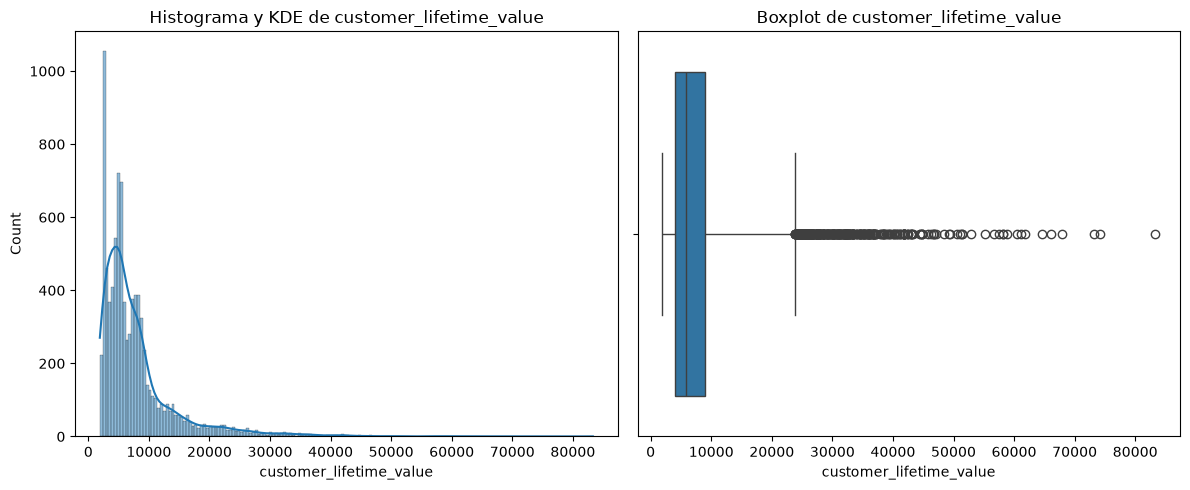

In [5]:
plot_combined_graphs(df_seguros, ["customer_lifetime_value"], whisker_width=3)  # bigotes de 3 veces el IQR (lo habitual es 1,5)

Ahora apliquemos nuestro doble plot a todas las columnas numéricas para ver que outliers deberíamos tratar:

#### Seguros: Detección de Outliers



(8, 2)


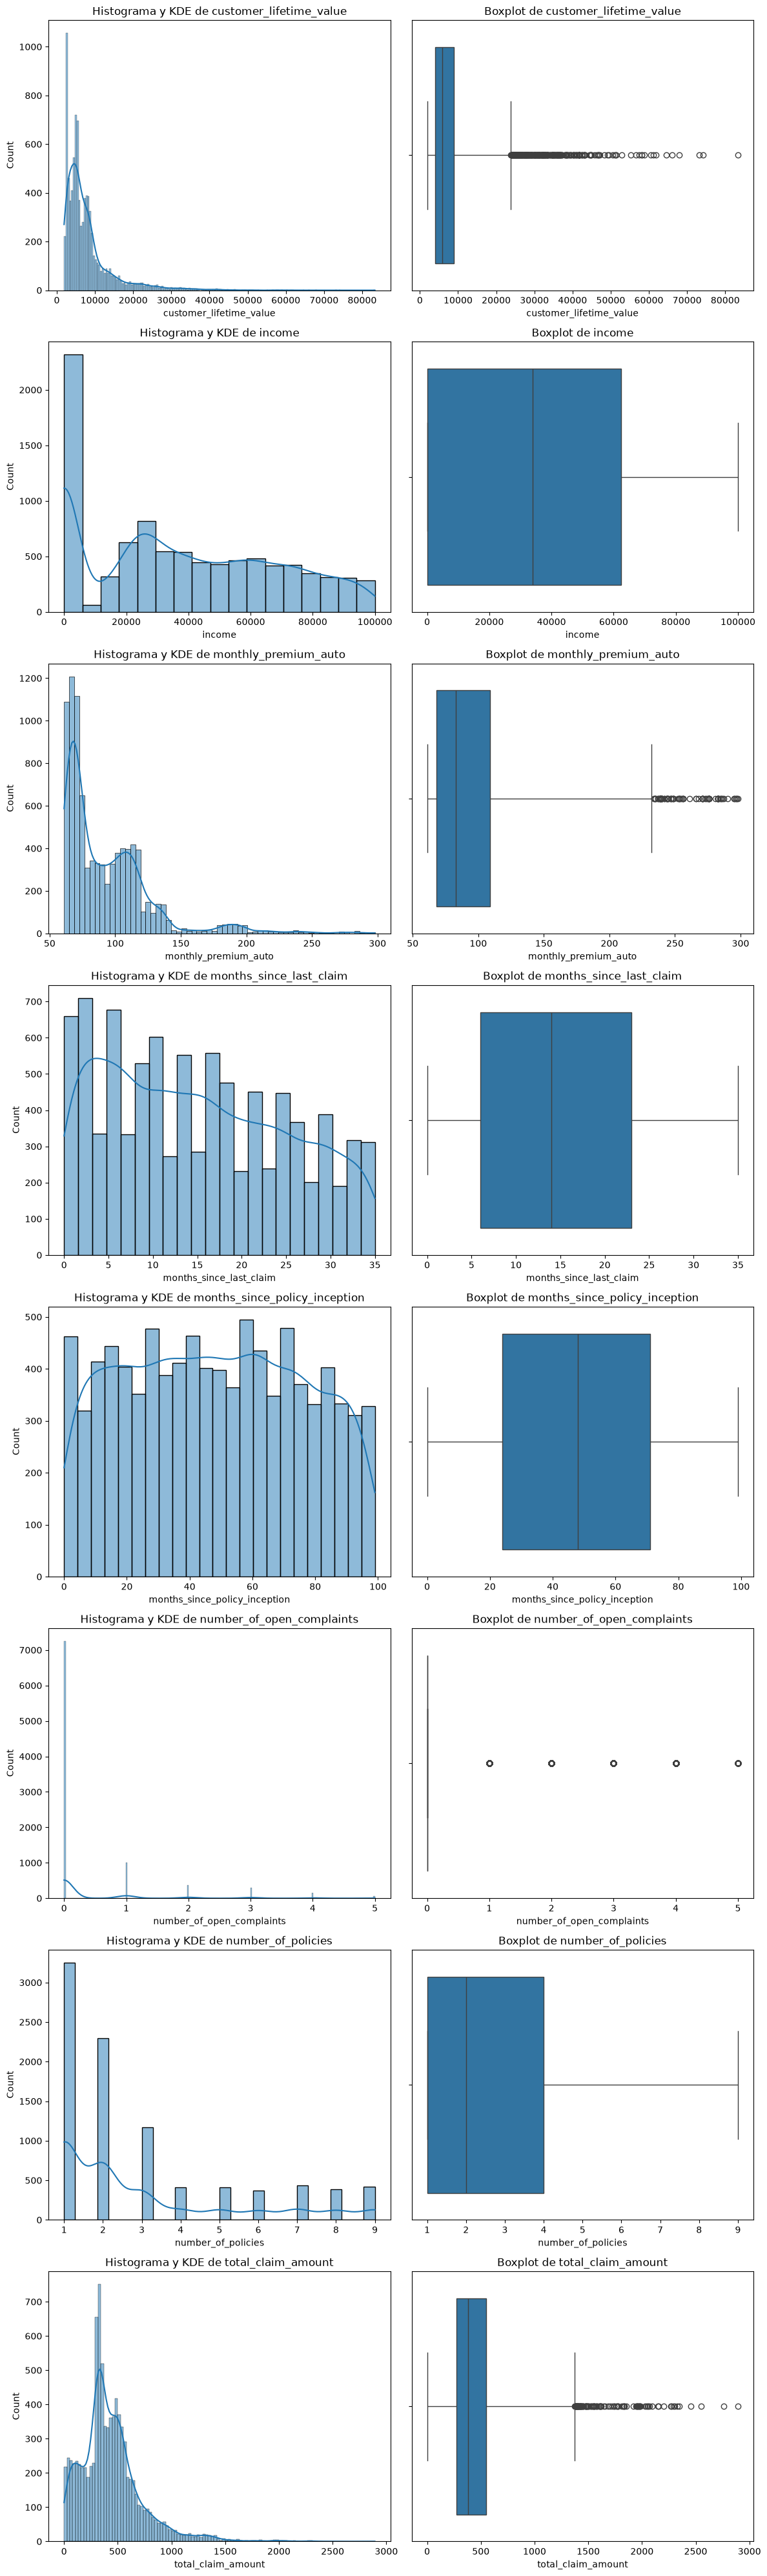

In [6]:
columnas_numericas = df_seguros.describe().columns.to_list()

plot_combined_graphs(df_seguros, columns = columnas_numericas, whisker_width=3)

Hay tres campos o variables claras sobre las que tratar los outliers:
* CLV, que además es prioritaria porque es una de las variables directoras o target.
* Monthly_premium_auto
* Total_claim_amount

Me apuntaría también un análisis que podría ser interesante, ¿coinciden los clientes de los tres outliers? ¿No, por qué?
Y otra cosa curiosa es el diagrama de caja del número de quejas... No me han pedido una análisis pero viendo que tener partes abiertos es un outlier en sí mismo, estudiaría la diferencia entre los clientes con quejas abiertas y sin quejas abiertas.

### ¿Y qué hacemos con ellos en el EDA?

Los outliers no son necesariamente malos; de hecho, habrá veces en que querrás cazarlos porque son precisamente esos valores los que te interesan. **No hay una regla única**: depende del problema y del contexto.

En el EDA nuestro objetivo es **entender** los datos, no modificarlos. Así que las decisiones que tomamos aquí son de análisis:
* Comprobar si son **errores** (un valor imposible, una edad de 200 años...) y anotarlo.
* **Mantenerlos** y tenerlos en cuenta al interpretar (por ejemplo, usando la mediana en lugar de la media).
* **Analizarlos por separado**: estudiar ese grupo de valores extremos como un segmento propio.

> Las técnicas para **modificar** los datos (eliminar filas, recortar o "capar" valores, imputarlos como si fueran nulos...) las veremos en el módulo de **Data Cleaning**, notebook `03_Tratamiento_Outliers`. Y las transformaciones matemáticas (logaritmos, Box-Cox...) en el preprocesado para Machine Learning.

#### Seguros: ¿qué hacemos con los outliers?

En este caso al ser CLV la variable casi más importante, descartamos eliminarlos, mi sugerencia sería:
1. Asegurarnos de que no son valores erróneos (no tiene pinta)
2. Dividir el dataset en dos, hacer un estudio para unos y otros.
3. Previamente analizar como se relacionan con las otras dos columnas de outliers. 

Una vez separados los datasets, analizar los nuevos outliers  (es decir ya en el dataset de outliers de CLV estos ya no son outliers, pero puede que haya outliers en los otros campos):
1. Categorizar las variables con outliers, rehacer su análisis tal como hicimos con las otras categóricas. 